# 05b · XGBoost with road-graph neighbour features (spatial tree baseline)

**Why this notebook.** Notebook 05's XGBoost sees each sensor in isolation, so "ST-GAT beats XGBoost" mixes two things: the use of neighbouring sensors and
the different model family. Here the **same** XGBoost (same rows, hyper-parameters, residual target, validation early stopping) additionally receives
features of each sensor's **road-graph neighbours**. If this closes most of the gap to the ST-GAT, the benefit comes from spatial information rather than from the
neural architecture.

**Neighbour features** (`feature_engineering.build_neighbour_features`), separately for upstream (edge `j -> i`) and downstream (`i -> j`) neighbours of the validated
road graph: edge-weighted mean speed at the origin and 15 minutes earlier, the slowest neighbour at the origin, and how many neighbours are observed. Only readings at or
before the origin are used (unit-tested); missing neighbours are ignored, never treated as zero.

> **Provenance.** `RETRAIN = False` reloads the saved models if they exist (and fits them otherwise); the fit was run once in an earlier execution of this notebook.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore", category=FutureWarning)

# Locate the project root (the folder that contains src/config.py) wherever Jupyter was started.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
sys.path.insert(0, str(ROOT))

from src import config
config.ensure_dirs()
print(f"project root : .../{ROOT.name}  (absolute paths are not printed)")
print(f"run mode     : {config.RUN_MODE}" + ("   <-- SMOKE TEST: outputs are NOT final results" if config.IS_SMOKE else ""))

project root : .../traffic-flow-control  (absolute paths are not printed)
run mode     : full


In [2]:
import json, time
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src import data_loader as dl, graph_utils as gu, preprocessing as pp, feature_engineering as fe, xgboost_model as xm, evaluation as ev, visualization as viz

viz.apply_style()
dl.require_raw_files()
ctx = pp.load_context()
graph = gu.load_graph_artifacts(expected_sensor_ids=ctx.sensor_ids)
N, HZ = len(ctx.sensor_ids), config.HORIZONS
lat, lon = graph.locations["latitude"].to_numpy(), graph.locations["longitude"].to_numpy()
RETRAIN = False
PREFIX, KEY = "xgb_spatial", "xgboost_spatial"

## 1 · Feature matrices (base features of notebook 05 + neighbour features)

In [3]:
origin_sets = {"train": ctx.origins["train"][::config.XGB_TRAIN_STRIDE], "val_fit": ctx.origins["val"][::config.XGB_VAL_STRIDE],
               "val": ctx.origins["val"], "test": ctx.origins["test"]}
FEATS, NAMES = {}, None
for name, o in origin_sets.items():
    base, base_names = fe.build_base_features(ctx.speed, ctx.locf_value, ctx.locf_age, ctx.scaler.sensor_mean, o, lat, lon)
    nbr, nbr_names = fe.build_neighbour_features(ctx.speed, graph.adjacency, o)
    FEATS[name] = np.hstack([base, nbr]); NAMES = base_names + nbr_names
    print(f"{name:8s}: {FEATS[name].shape[0]:>9,} rows x {FEATS[name].shape[1]} features ({FEATS[name].nbytes / 1e6:.0f} MB)")
ANCHOR = NAMES.index("last_observed")
print("neighbour features:", nbr_names)
nbr_block = FEATS["test"][:, len(base_names):]
print("share of rows with no observed upstream / downstream neighbour (isolated sensor or missing data):",
      f"{np.isnan(nbr_block[:, nbr_names.index('up_mean_lag0')]).mean():.1%} / {np.isnan(nbr_block[:, nbr_names.index('down_mean_lag0')]).mean():.1%}")

def design(split, h):
    hz, hz_names = fe.horizon_features(ctx.timestamps, origin_sets[split], h, N)
    return fe.to_frame(FEATS[split], NAMES, hz, hz_names, N)

def targets(split, h):
    o = origin_sets[split]
    y = ctx.speed[o + h].reshape(-1); ok = ctx.mask[o + h].reshape(-1)
    return y - FEATS[split][:, ANCHOR], ok

train   : 2,471,787 rows x 32 features (316 MB)
val_fit :   237,843 rows x 32 features (30 MB)


val     :   713,115 rows x 32 features (91 MB)


test    : 1,428,507 rows x 32 features (183 MB)
neighbour features: ['up_mean_lag0', 'up_min_lag0', 'up_n_observed', 'up_mean_lag3', 'down_mean_lag0', 'down_min_lag0', 'down_n_observed', 'down_mean_lag3']
share of rows with no observed upstream / downstream neighbour (isolated sensor or missing data): 10.8% / 12.1%


## 2 · Fit one model per horizon (identical settings to notebook 05)

In [4]:
curves_path = config.METRICS_DIR / f"{config.tagged(PREFIX)}_validation_curves.json"
models, fit_info = {}, {}
if not RETRAIN and all(xm.model_path(h, PREFIX).is_file() for h in HZ) and curves_path.is_file():
    saved = json.loads(curves_path.read_text())
    for h in HZ:
        models[h] = xm.load_model(h, PREFIX); fit_info[h] = saved["fit_info"][str(h)]
    print("reloaded the saved models (fitted in an earlier execution)")
else:
    curves = {}
    for h in HZ:
        t0 = time.time()
        X_tr, (r_tr, ok_tr) = design("train", h), targets("train", h)
        X_va, (r_va, ok_va) = design("val_fit", h), targets("val_fit", h)
        m = xm.fit_horizon_model(X_tr[ok_tr], r_tr[ok_tr], X_va[ok_va], r_va[ok_va])
        models[h] = m; curves[h] = m.evals_result()["validation_0"]["mae"]
        fit_info[h] = {"horizon_min": h * 5, "train_rows": int(ok_tr.sum()), "best_iteration": int(m.best_iteration) + 1,
                       "val_residual_MAE": float(min(curves[h])), "seconds": round(time.time() - t0)}
        print(f"h={h:2d}: best iteration {fit_info[h]['best_iteration']}, validation residual MAE {fit_info[h]['val_residual_MAE']:.3f} mph, {fit_info[h]['seconds']}s")
        del X_tr, X_va
    xm.save_models(models, {"seed": config.SEED, "feature_names": NAMES, "fit_info": {str(k): v for k, v in fit_info.items()}}, prefix=PREFIX)
    curves_path.write_text(json.dumps({"curves": {str(k): v for k, v in curves.items()}, "fit_info": {str(k): v for k, v in fit_info.items()}}))
display(pd.DataFrame(fit_info).T)

h= 1: best iteration 1492, validation residual MAE 2.088 mph, 265s


h= 3: best iteration 1500, validation residual MAE 2.556 mph, 268s


h= 6: best iteration 1476, validation residual MAE 2.955 mph, 273s


h=12: best iteration 1500, validation residual MAE 3.415 mph, 244s


,horizon_min,train_rows,best_iteration,val_residual_MAE,seconds
1,5.0,2296387.0,1492.0,2.088368,265.0
3,15.0,2296389.0,1500.0,2.555772,268.0
6,30.0,2293530.0,1476.0,2.955285,273.0
12,60.0,2293535.0,1500.0,3.414736,244.0


## 3 · How much do the trees use the neighbour features?

,share of gain from neighbour features,top feature,best neighbour feature
5 min,0.110882,roll_mean_12,down_mean_lag0
15 min,0.110505,last_observed,down_mean_lag0
30 min,0.106266,last_observed,up_mean_lag0
60 min,0.090457,last_observed,down_n_observed


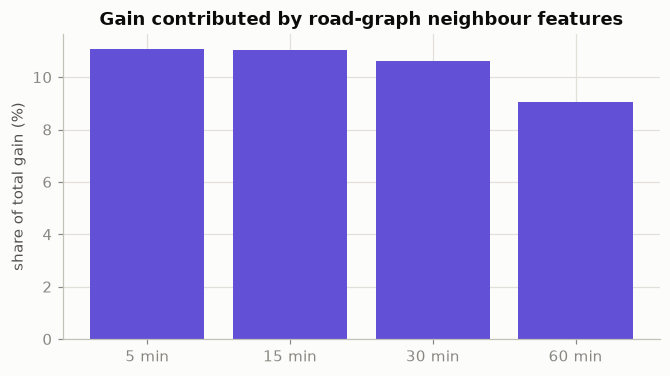

In [5]:
rows = {}
for h in HZ:
    g = pd.Series(models[h].get_booster().get_score(importance_type="gain")); g = g / g.sum()
    rows[f"{h * 5} min"] = {"share of gain from neighbour features": g[[c for c in g.index if c.startswith(("up_", "down_"))]].sum(),
                            "top feature": g.idxmax(), "best neighbour feature": g[[c for c in g.index if c.startswith(("up_", "down_"))]].idxmax()}
importance = pd.DataFrame(rows).T
display(importance)
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.bar(importance.index, importance["share of gain from neighbour features"].astype(float) * 100, color=viz.style(KEY)["color"])
ax.set_ylabel("share of total gain (%)"); ax.set_title("Gain contributed by road-graph neighbour features")
viz.save_figure(fig, "05b_neighbour_feature_gain"); plt.show()

## 4 · Forecasts (validation and test) and validation comparison

In [6]:
preds = {}
for split in ("val", "test"):
    out = np.empty((len(origin_sets[split]), len(HZ), N), dtype=np.float32)
    for j, h in enumerate(HZ):
        out[:, j, :] = xm.predict_speed(models[h], design(split, h)).reshape(-1, N)
    assert np.isfinite(out).all()
    ev.save_predictions(KEY, split, out, origin_sets[split], HZ, {"model": KEY, "units": "mph", "run_mode": config.RUN_MODE})
    preds[split] = out
val_preds = {KEY: ev.clip_predictions(preds["val"])}
for other in ("xgboost", "gat"):
    d = ev.load_predictions(other, "val"); assert np.array_equal(d["origins"], origin_sets["val"]); val_preds[other] = d["pred"]
yv, mv = pp.gather_targets(ctx.speed, ctx.mask, origin_sets["val"], HZ)
valid = ev.common_valid_mask(val_preds, mv)
table = ev.metrics_by_horizon(val_preds, yv, valid, HZ)
display(table.pivot(index="model", columns="horizon_min", values=["MAE", "RMSE"]).round(3))
print("Validation only; the test-period comparison with intervals is in notebook 07.")

MAE                        RMSE                     
horizon_min         5      15     30     60     5      15     30     60
model                                                                  
gat              2.116  2.513  2.849  3.242  3.691  4.851  5.796  6.811
xgboost          2.159  2.642  3.050  3.495  3.827  5.261  6.290  7.221
xgboost_spatial  2.081  2.562  2.961  3.419  3.607  4.965  5.989  6.976

Validation only; the test-period comparison with intervals is in notebook 07.
